# Marginalised limb darkening: emcee and importance sampling

This notebook follows pizzetti's [example 01](https://github.com/hippke/pizzetti/blob/main/examples/01_batman_dropin_emcee.ipynb)
(simulated hot Jupiter, 7 transits, 2-min cadence, 500 ppm, quadratic limb darkening) and fits it three ways:

| | method | what the sampler sees |
|---|---|---|
| **A₀** | example 01 with batman: `batman.TransitModel` + the same `log_prob` + `emcee` (fixed-budget timing only) | t0, per, rp, a, b, q1, q2 (7-D) |
| **A** | the original notebook: `pizzetti.TransitModel` + hand-written `log_prob` + `emcee` | t0, per, rp, a, b, q1, q2 (7-D) |
| **B** | `pizzetti.MarginalTransitModel` + `model.EnsembleSampler` (an `emcee.EnsembleSampler` subclass) | t0, per, rp, a, b (5-D) |
| **C** | `pizzetti.MarginalTransitModel.fit()`: profile importance sampling, no MCMC | t0, per, rp, a, b (5-D) |

In B and C the quadratic limb-darkening coefficients **and** the out-of-transit flux are integrated out analytically over their
physical region (Kipping 2013 conditions, uniform prior on q1, q2), then drawn back for every posterior sample. The user code for B
differs from A by about three lines.

*Timing note: wall-clock times depend on the machine and its load; evaluation counts and autocorrelation times do not
(they do vary with the random seed, especially for A, whose low-b tail mixes slowly; all runs here are seeded).*

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
import batman
import pizzetti

print("batman", batman.__version__, "| pizzetti", pizzetti.__version__, "| emcee", emcee.__version__)

batman 2.5.1 | pizzetti 0.2.1+terms | emcee 3.1.6


## Data (identical to example 01)

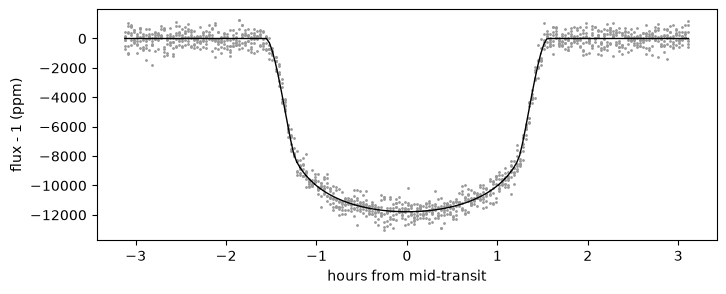

In [2]:
truth = dict(t0=0.0, per=3.5, rp=0.10, a=9.0, b=0.35, u1=0.40, u2=0.25)
sigma = 500e-6

epochs = np.arange(7)
t_one = np.arange(-0.13, 0.13, 2.0 / 1440)
t = (truth["t0"] + epochs[:, None] * truth["per"] + t_one[None, :]).ravel()

def params(module, t0, per, rp, a, b, u1, u2):
    p = module.TransitParams()
    p.t0, p.per, p.rp, p.a = t0, per, rp, a
    p.inc = np.degrees(np.arccos(b / a))
    p.ecc, p.w = 0.0, 90.0
    p.limb_dark, p.u = "quadratic", [u1, u2]
    return p

p_true = params(pizzetti, **truth)
f_true = pizzetti.TransitModel(p_true, t, series_tol=0.0, limb="quadrature").light_curve(p_true)
y = f_true + sigma * np.random.default_rng(42).standard_normal(t.size)

fold = (t - truth["t0"] + 0.5 * truth["per"]) % truth["per"] - 0.5 * truth["per"]
plt.figure(figsize=(8, 3))
plt.plot(24 * fold, 1e6 * (y - 1), ".", ms=2, color="0.6")
plt.plot(24 * np.sort(fold), 1e6 * (f_true[np.argsort(fold)] - 1), "k", lw=1)
plt.xlabel("hours from mid-transit"); plt.ylabel("flux - 1 (ppm)");

## Common settings

Same starting points as example 01. All emcee runs continue until the emcee convergence recipe is met
(chain longer than 50 autocorrelation times, τ estimate stable to 1 %), so the comparison is
**effort to convergence**, not effort for a fixed number of steps.

In [3]:
u1, u2 = truth["u1"], truth["u2"]
th0 = np.array([truth["t0"], truth["per"], truth["rp"], truth["a"], truth["b"],
                (u1 + u2)**2, u1 / (2 * (u1 + u2))])
nwalkers = 32
p0 = th0 + np.array([2e-4, 2e-6, 1e-3, 0.05, 0.02, 0.02, 0.02]) * np.random.default_rng(1234).standard_normal((nwalkers, 7))

def run_to_convergence(sampler, p0, ntau=50, check=500, max_steps=200_000, seed=2024):
    sampler.random_state = np.random.RandomState(seed).get_state()     # reproducible
    t_start = time.perf_counter()
    old = np.inf
    for _ in sampler.sample(p0, iterations=max_steps):
        if sampler.iteration % check:
            continue
        tau = sampler.get_autocorr_time(tol=0)
        if np.all(ntau * tau < sampler.iteration) and np.all(np.abs(old - tau) / tau < 0.01):
            break
        old = tau
    wall = time.perf_counter() - t_start
    tau = sampler.get_autocorr_time(tol=0)
    return dict(wall=wall, steps=sampler.iteration, evals=sampler.iteration * sampler.nwalkers,
                tau=tau, burn=int(5 * tau.max()))

## A. The original notebook: `TransitModel` + hand-written `log_prob` + emcee

In [4]:
names = ["t0", "per", "rp", "a", "b", "q1", "q2"]

def to_u(q1, q2):
    s = np.sqrt(q1)
    return 2 * s * q2, s * (1 - 2 * q2)

prm = params(pizzetti, **truth)
model_A = pizzetti.TransitModel(prm, t)
n_eval_A = 0

def log_prob(th):
    global n_eval_A
    n_eval_A += 1
    t0, per, rp, a, b, q1, q2 = th
    if not (0 < rp < 0.5 and 1.5 < a < 100 and 0 <= b < 1 + rp and 0 < q1 < 1 and 0 < q2 < 1):
        return -np.inf
    prm.t0, prm.per, prm.rp, prm.a = t0, per, rp, a
    prm.inc = np.degrees(np.arccos(b / a))
    prm.u = list(to_u(q1, q2))
    r = y - model_A.light_curve(prm)
    return -0.5 * np.dot(r, r) / sigma**2

log_prob(p0[0])                                       # warm-up (numba compilation)
sampler_A = emcee.EnsembleSampler(nwalkers, 7, log_prob)
res_A = run_to_convergence(sampler_A, p0)
chain_A = sampler_A.get_chain(discard=res_A["burn"], flat=True)
print(f"A: {res_A['steps']} steps, {res_A['evals']} evaluations, max tau {res_A['tau'].max():.0f}, {res_A['wall']:.1f} s")

A: 23500 steps, 752000 evaluations, max tau 469, 44.2 s


## B. New method, emcee API

`MarginalTransitModel` takes the same `TransitParams` plus the data. Its `EnsembleSampler` is an
`emcee.EnsembleSampler` subclass, so progress bars, backends, `get_autocorr_time` etc. all work as usual.
The old 7-column `p0` is accepted as is (the q1, q2 columns are ignored), and `get_chain` returns
t0, per, rp, a, b **plus** q1, q2 and the baseline f0, drawn from their exact conditional posterior.
Internally the sampler uses the transit duration T14 instead of a/R* (prior kept uniform in a), and all
walkers of a half-ensemble are evaluated in one compiled call.

In [5]:
model = pizzetti.MarginalTransitModel(p_true, t, y, sigma,
                                      free=["t0", "per", "rp", "a", "b"],
                                      bounds={"rp": (0, 0.5), "a": (1.5, 100)})
model.log_prob_internal(model.to_internal(p0[:4, :5]))      # warm-up (numba compilation)
model.n_eval = 0
sampler_B = model.EnsembleSampler(nwalkers)
res_B = run_to_convergence(sampler_B, p0)
res_B["evals"] = model.n_eval
chain_B = sampler_B.get_chain(discard=res_B["burn"], flat=True, seed=1)
print(sampler_B.labels)
print(f"B: {res_B['steps']} steps, {res_B['evals']} evaluations, max tau {res_B['tau'].max():.0f}, {res_B['wall']:.1f} s")

['t0', 'per', 'rp', 'a', 'b', 'q1', 'q2', 'f0']
B: 10500 steps, 336032 evaluations, max tau 120, 11.6 s


## C. New method, one call (no MCMC)

`fit()` finds the posterior maximum, builds a proposal along the impact parameter from conditional optima
(which covers the b ≥ 0 wall and skewed tails), and importance-samples with Pareto-smoothed weights.
If the diagnostics fail (k̂ ≥ 0.7 or an incomplete profile) it falls back to emcee automatically.

In [6]:
model.n_eval = 0
t_start = time.perf_counter()
result = model.fit(seed=1, n=8000)
wall_C = time.perf_counter() - t_start
print(result.diagnostics)
print(result.summary())

{'method': 'profile-IS', 'khat': -0.1877327512811377, 'ess': 5885.255663995944, 'complete': True, 'n_grid': 17, 'is_ok': True, 'n_eval': 17751, 'ld_reweight_ess': 7997.13954130859}
              median     -1sigma     +1sigma
t0     -0.0001424167    0.000115    0.000114
per         3.500054    3.13e-05    3.14e-05
rp        0.09962947    0.000751    0.000643
a           9.169914       0.134       0.158
b          0.2993921      0.0694      0.0472
q1         0.3939778      0.0609      0.0762
q2         0.3456302      0.0603      0.0654
f0         0.9999856    1.93e-05    1.86e-05


## Performance

In [7]:
def ess_per_sec(res):
    # effective samples of the worst-mixing parameter after burn-in, per second of sampling
    n = (res["steps"] - res["burn"]) * nwalkers
    return n / res["tau"].max(), n / res["tau"].max() / res["wall"]

ess_A, essps_A = ess_per_sec(res_A)
ess_B, essps_B = ess_per_sec(res_B)
ess_C = result.diagnostics["ess"]
rows = [("A  TransitModel + emcee (7-D)", res_A["evals"], res_A["wall"], ess_A, essps_A),
        ("B  Marginal + emcee (5-D)", res_B["evals"], res_B["wall"], ess_B, essps_B),
        ("C  Marginal + fit() (IS)", result.diagnostics["n_eval"], wall_C, ess_C, ess_C / wall_C)]
print(f"{'':32s} {'evaluations':>12s} {'wall [s]':>9s} {'ESS':>8s} {'ESS/s':>9s}")
for r in rows:
    print(f"{r[0]:32s} {r[1]:12d} {r[2]:9.1f} {r[3]:8.0f} {r[4]:9.1f}")
print(f"\nevaluations to convergence, A / B: {res_A['evals'] / res_B['evals']:.1f}x;   A / C: {res_A['evals'] / result.diagnostics['n_eval']:.0f}x")
print(f"ESS per second, B / A: {essps_B / essps_A:.1f}x;   C / A: {(ess_C / wall_C) / essps_A:.0f}x")

                                  evaluations  wall [s]      ESS     ESS/s
A  TransitModel + emcee (7-D)          752000      44.2     1442      32.6
B  Marginal + emcee (5-D)              336032      11.6     2637     226.7
C  Marginal + fit() (IS)                17751       0.6     5885    9707.0

evaluations to convergence, A / B: 2.2x;   A / C: 42x
ESS per second, B / A: 7.0x;   C / A: 298x


## Same budget as example 01 (fixed 3000 steps), including batman

Example 01 runs batman + emcee and pizzetti + emcee for a fixed 3000 steps with identical likelihoods
(default settings of each package). Here the same is done for batman (**A₀**), pizzetti (**A**) and the
marginalised model (**B**), alternating, best of three. Note that 3000 steps is short of emcee's 50τ
recommendation for A (and τ is underestimated in short runs); the convergence-based comparison above is
the fair measure of effort, this one shows the cost per step.

In [8]:
def make_log_prob(module):
    # example 01's likelihood, for either package (default model settings)
    prm = params(module, **truth)
    m = module.TransitModel(prm, t)
    def lp(th):
        t0, per, rp, a, b, q1, q2 = th
        if not (0 < rp < 0.5 and 1.5 < a < 100 and 0 <= b < 1 + rp and 0 < q1 < 1 and 0 < q2 < 1):
            return -np.inf
        prm.t0, prm.per, prm.rp, prm.a = t0, per, rp, a
        prm.inc = np.degrees(np.arccos(b / a))
        prm.u = list(to_u(q1, q2))
        r = y - m.light_curve(prm)
        return -0.5 * np.dot(r, r) / sigma**2
    lp(p0[0])                                         # warm-up
    return lp

configs = {"A0 batman + emcee (7-D)": lambda lp=make_log_prob(batman): emcee.EnsembleSampler(nwalkers, 7, lp),
           "A  pizzetti + emcee (7-D)": lambda lp=make_log_prob(pizzetti): emcee.EnsembleSampler(nwalkers, 7, lp),
           "B  Marginal + emcee (5-D)": lambda: model.EnsembleSampler(nwalkers)}
walls = {k: [] for k in configs}
for rep in range(3):
    for k in (list(configs) if rep % 2 == 0 else list(configs)[::-1]):
        s = configs[k]()
        s.random_state = np.random.RandomState(2024).get_state()
        t1 = time.perf_counter()
        s.run_mcmc(p0, 3000, progress=False)
        walls[k].append(time.perf_counter() - t1)
        if rep == 0:
            ch = s.get_chain(expand=False) if k.startswith("B") else s.get_chain()
            walls[k + " tau"] = emcee.autocorr.integrated_time(ch, quiet=True, tol=0).max()
print(f"{'3000 steps x 32 walkers':28s} {'best wall [s]':>13s} {'us/eval':>8s} {'max tau':>8s} {'ESS/s':>7s}")
for k in configs:
    w, tau = min(walls[k]), walls[k + " tau"]
    print(f"{k:28s} {w:13.2f} {w / 96000 * 1e6:8.1f} {tau:8.0f} {64000 / tau / w:7.0f}")
wb, wp, wm = (min(walls[k]) for k in configs)
print(f"\nspeed-up per step vs batman: pizzetti {wb / wp:.1f}x, marginal {wb / wm:.1f}x")

3000 steps x 32 walkers      best wall [s]  us/eval  max tau   ESS/s
A0 batman + emcee (7-D)               7.12     74.2      147      61
A  pizzetti + emcee (7-D)             2.82     29.3      152     150
B  Marginal + emcee (5-D)             2.69     28.1       75     315

speed-up per step vs batman: pizzetti 2.5x, marginal 2.6x


## Posteriors

A fixes the baseline flux to 1 (as in example 01); B and C fit it (it is integrated out). The geometry and
limb-darkening posteriors agree within their Monte Carlo noise.

In [9]:
sel_A = chain_A
lab = ["rp", "a", "b", "q1", "q2"]
X_A = chain_A[:, [names.index(k) for k in lab]]
X_B = chain_B[:, [sampler_B.labels.index(k) for k in lab]]
X_C = result.samples[:, [result.labels.index(k) for k in lab]]

print(f"{'':4s} {'truth':>8s} {'A (median ± sd)':>22s} {'B':>22s} {'C':>22s} {'(B-A)/σ':>8s} {'(C-A)/σ':>8s}")
tq = {"rp": truth["rp"], "a": truth["a"], "b": truth["b"], "q1": th0[5], "q2": th0[6]}
for j, k in enumerate(lab):
    a, b, c = X_A[:, j], X_B[:, j], X_C[:, j]
    print(f"{k:4s} {tq[k]:8.4f} {np.median(a):10.5f} ± {a.std():.5f} {np.median(b):10.5f} ± {b.std():.5f} "
          f"{np.median(c):10.5f} ± {c.std():.5f} {(np.median(b) - np.median(a)) / a.std():+8.2f} {(np.median(c) - np.median(a)) / a.std():+8.2f}")

        truth        A (median ± sd)                      B                      C  (B-A)/σ  (C-A)/σ


rp     0.1000    0.09970 ± 0.00070    0.09965 ± 0.00071    0.09963 ± 0.00070    -0.08    -0.11
a      9.0000    9.16245 ± 0.14469    9.16926 ± 0.14819    9.16991 ± 0.14858    +0.05    +0.05
b      0.3500    0.30051 ± 0.06419    0.29942 ± 0.06767    0.29939 ± 0.06875    -0.02    -0.02
q1     0.4225    0.39669 ± 0.07144    0.39403 ± 0.07044    0.39398 ± 0.07023    -0.04    -0.04
q2     0.3077    0.34184 ± 0.06559    0.34473 ± 0.06513    0.34563 ± 0.06387    +0.04    +0.06


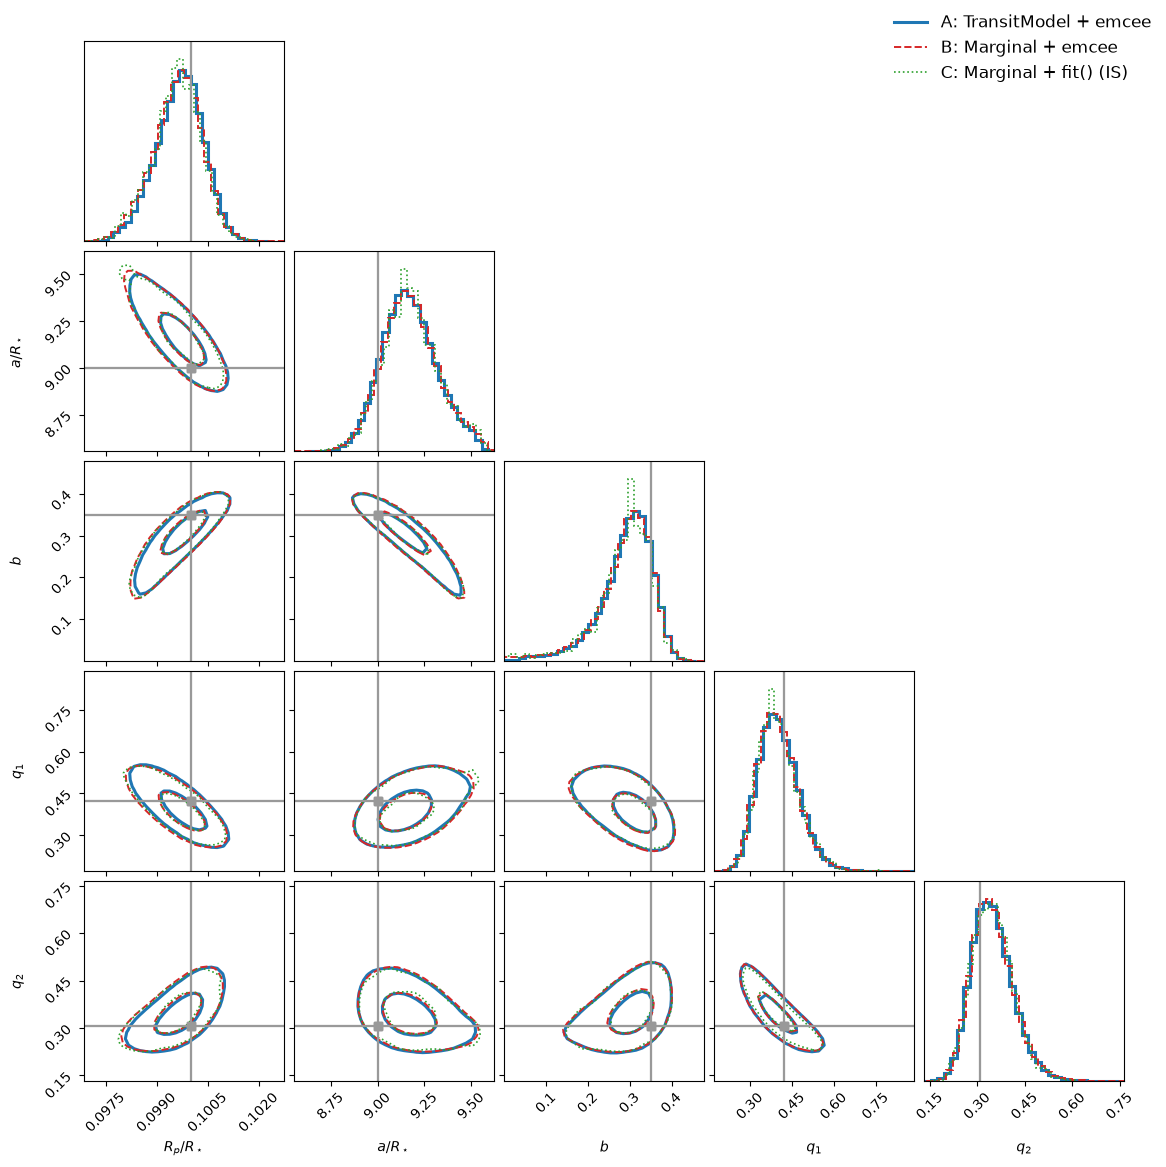

In [10]:
labels = [r"$R_p/R_\star$", r"$a/R_\star$", r"$b$", r"$q_1$", r"$q_2$"]
kw = dict(labels=labels, bins=30, smooth=1.0, levels=(0.393, 0.865), plot_datapoints=False,
          plot_density=False, truths=[tq[k] for k in lab], truth_color="0.6")
fig = corner.corner(X_A, color="C0", hist_kwargs=dict(lw=2.2, density=True), contour_kwargs=dict(linewidths=2.2), **kw)
corner.corner(X_B, fig=fig, color="C3", hist_kwargs=dict(lw=1.4, ls="--", density=True),
              contour_kwargs=dict(linewidths=1.4, linestyles="--"), **kw)
corner.corner(X_C, fig=fig, color="C2", hist_kwargs=dict(lw=1.2, ls=":", density=True),
              contour_kwargs=dict(linewidths=1.2, linestyles=":"), **kw)
fig.legend(handles=[plt.Line2D([], [], color="C0", lw=2.2, label="A: TransitModel + emcee"),
                    plt.Line2D([], [], color="C3", lw=1.4, ls="--", label="B: Marginal + emcee"),
                    plt.Line2D([], [], color="C2", lw=1.2, ls=":", label="C: Marginal + fit() (IS)")],
           loc="upper right", fontsize=12, frameon=False);

## What changed in the user code (A → B)

```python
# A (example 01)                                    # B (new)
model = pizzetti.TransitModel(prm, t)               model = pizzetti.MarginalTransitModel(p_true, t, y, sigma,
def log_prob(th): ...  # ~10 lines                          free=["t0", "per", "rp", "a", "b"],
sampler = emcee.EnsembleSampler(32, 7, log_prob)            bounds={"rp": (0, 0.5), "a": (1.5, 100)})
                                                    sampler = model.EnsembleSampler(32)
sampler.run_mcmc(p0, nsteps)                        sampler.run_mcmc(p0, nsteps)          # same p0
chain = sampler.get_chain(discard=..., flat=True)   chain = sampler.get_chain(discard=..., flat=True)
```

Or, for the fastest route, `result = model.fit()`.

**Scope (current):** quadratic limb darkening, primary transits, rp > 0, circular or eccentric orbits, supersampling,
per-point errors, box priors, a vectorised `log_prior` on the geometry, and Gaussian priors on (u1, u2) (exact).
Other laws, secondary eclipses and inverse transits raise `NotImplementedError` for now.